# Customer Segmentation with K-Means Clustering (RFM Analysis)

**Goal:** Group customers into meaningful segments using Recency, Frequency
and Monetary (RFM) behavior, so marketing can target each group differently
— e.g. reward loyal customers, win back at-risk ones.

**Dataset:** `data/customers.csv` — 808 synthetic customers with:
- `Recency_Days` — days since their last order
- `Frequency_Orders` — number of orders placed
- `Monetary_Spend` — total amount spent

**Tools:** Python, Pandas, Scikit-learn (KMeans, StandardScaler), Matplotlib/Seaborn

**Sections:**
1. Load & clean the data
2. Feature scaling
3. Finding the right number of clusters (elbow method)
4. K-Means clustering
5. Interpreting the segments
6. Key findings


## 1. Load & Clean the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("data/customers.csv")
print("Raw shape:", df.shape)
df.head()

Raw shape: (808, 4)


,Customer_ID,Recency_Days,Frequency_Orders,Monetary_Spend
0,CUST-5008,17,31,3857.29
1,CUST-5510,115,3,176.48
2,CUST-5175,2,23,2016.93
3,CUST-5735,24,2,1816.48
4,CUST-5242,15,14,1540.14


In [2]:
print("Duplicates:", df.duplicated().sum())
print("Nulls:\n", df.isnull().sum()[df.isnull().sum() > 0])

Duplicates: 8
Nulls:
 Monetary_Spend    15
dtype: int64


In [3]:
df = df.drop_duplicates()
df["Monetary_Spend"] = df["Monetary_Spend"].fillna(df["Monetary_Spend"].median())
print("Cleaned shape:", df.shape)
df[["Recency_Days", "Frequency_Orders", "Monetary_Spend"]].describe().round(1)

Cleaned shape: (800, 4)


,Recency_Days,Frequency_Orders,Monetary_Spend
count,800.0,800.0,800.0
mean,38.9,10.3,1870.6
std,46.5,11.0,1524.4
min,1.0,1.0,57.3
25%,11.0,2.0,705.9
50%,18.0,6.0,1536.4
75%,36.0,14.2,2644.6
max,179.0,39.0,5987.9


## 2. Feature Scaling

K-Means uses distance between points, so features need to be on the same
scale — otherwise Monetary_Spend (in thousands) would dominate Recency_Days
(in tens) just because of its larger numbers.

In [4]:
features = ["Recency_Days", "Frequency_Orders", "Monetary_Spend"]
X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled[:5]

array([[-0.47163553,  1.87562081,  1.30405809],
       [ 1.63683375, -0.66037884, -1.11206736],
       [-0.79436042,  1.15104948,  0.09602491],
       [-0.32103058, -0.75095025, -0.03555275],
       [-0.51466552,  0.33590674, -0.21694546]])

## 3. Finding the Right Number of Clusters (Elbow Method)

Running K-Means for a range of k values and plotting the within-cluster sum
of squares (inertia) — the "elbow" in the curve is a reasonable choice for k.

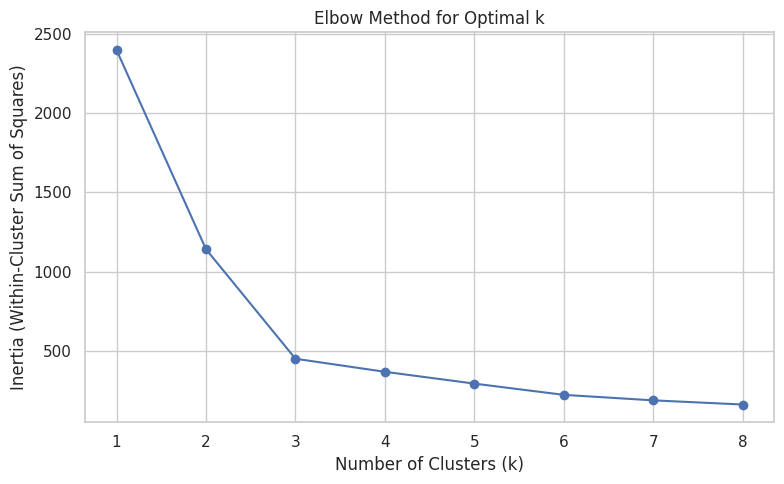

In [5]:
inertias = []
k_range = range(1, 9)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots()
ax.plot(list(k_range), inertias, marker="o")
ax.set_xlabel("Number of Clusters (k)")
ax.set_ylabel("Inertia (Within-Cluster Sum of Squares)")
ax.set_title("Elbow Method for Optimal k")
plt.tight_layout()
plt.savefig("charts/elbow_method.png", dpi=120)
plt.show()

The elbow flattens out around **k = 4**, so that's the value used below.

## 4. K-Means Clustering

In [6]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)
df["Cluster"].value_counts().sort_index()

Cluster
0    177
1    182
2    223
3    218
Name: count, dtype: int64

## 5. Interpreting the Segments

In [7]:
cluster_profile = df.groupby("Cluster")[features].mean().round(1)
cluster_profile["Customer_Count"] = df["Cluster"].value_counts().sort_index()
cluster_profile

,Recency_Days,Frequency_Orders,Monetary_Spend,Customer_Count
Cluster,,,,
0,119.2,2.0,237.5,177
1,10.2,28.1,4170.7,182
2,16.6,1.9,1832.2,223
3,20.6,10.7,1315.6,218


In [8]:
# Label clusters based on their profile (recency low = recent, monetary high = big spender)
def label_cluster(row):
    if row.Recency_Days > 60:
        return "At-Risk / Churned"
    elif row.Frequency_Orders >= 15:
        return "Loyal High-Spenders"
    elif row.Monetary_Spend >= 800 and row.Frequency_Orders < 5:
        return "New Big Spenders"
    else:
        return "Regular Customers"

cluster_profile["Segment_Label"] = cluster_profile.apply(label_cluster, axis=1)
cluster_profile

,Recency_Days,Frequency_Orders,Monetary_Spend,Customer_Count,Segment_Label
Cluster,,,,,
0,119.2,2.0,237.5,177,At-Risk / Churned
1,10.2,28.1,4170.7,182,Loyal High-Spenders
2,16.6,1.9,1832.2,223,New Big Spenders
3,20.6,10.7,1315.6,218,Regular Customers


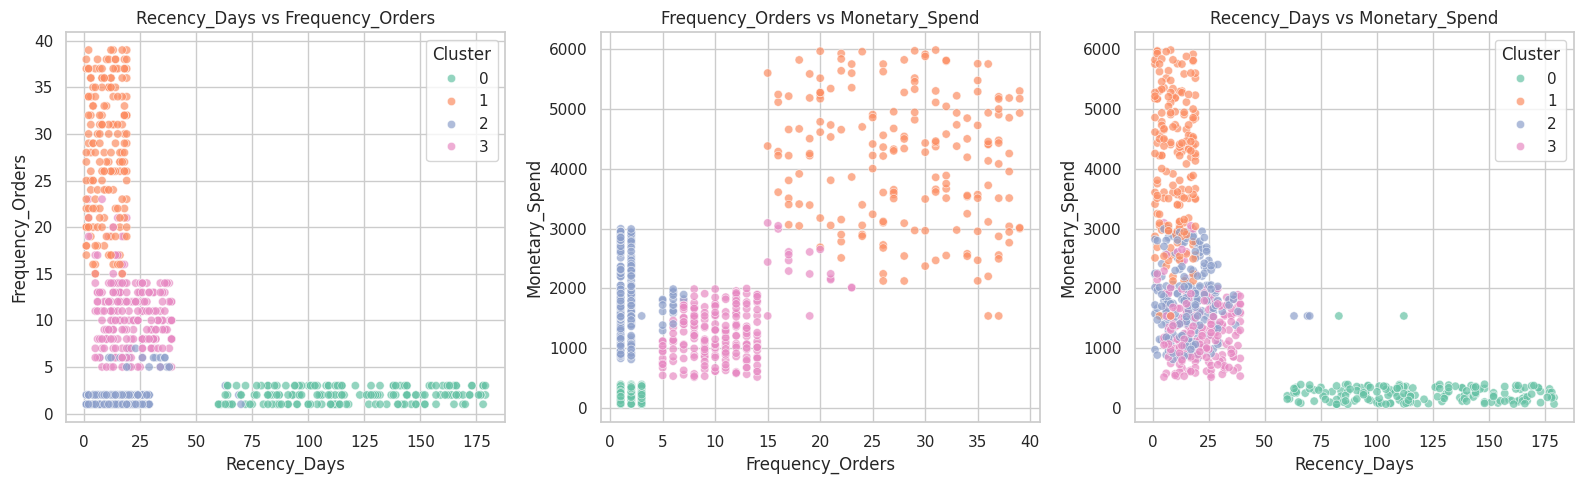

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
pairs = [("Recency_Days", "Frequency_Orders"),
         ("Frequency_Orders", "Monetary_Spend"),
         ("Recency_Days", "Monetary_Spend")]
for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(data=df, x=x, y=y, hue="Cluster", palette="Set2", alpha=0.7, ax=ax, legend=(x==pairs[0][0]))
    ax.set_title(f"{x} vs {y}")
plt.tight_layout()
plt.savefig("charts/cluster_scatter_pairs.png", dpi=120)
plt.show()

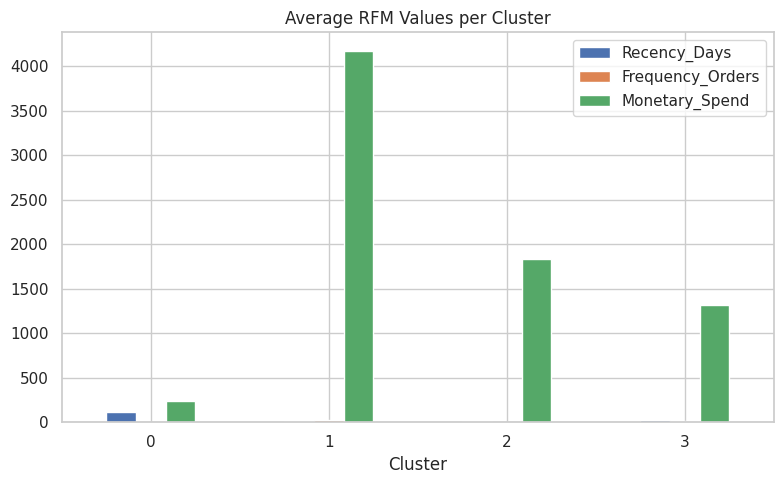

In [10]:
fig, ax = plt.subplots()
cluster_profile[features].plot(kind="bar", ax=ax)
ax.set_title("Average RFM Values per Cluster")
ax.set_xlabel("Cluster")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("charts/cluster_profile_bar.png", dpi=120)
plt.show()

## 6. Key Findings

- K-Means with k=4 cleanly separates customers into **Loyal High-Spenders**,
  **Regular Customers**, **At-Risk/Churned**, and **New Big Spenders** —
  confirmed by the elbow method and the cluster profile table.
- **At-Risk customers** have high recency (haven't purchased recently) and
  low frequency — a clear list to target with a win-back campaign.
- **Loyal High-Spenders** are a small but valuable group — worth a loyalty
  or VIP program to retain them.
- **New Big Spenders** placed few orders but spent a lot per order — good
  candidates for a "welcome" cross-sell campaign to increase order frequency.
- Scaling the features before clustering was essential — without it,
  Monetary_Spend (largest numeric range) would have dominated the distance
  calculation and distorted the clusters.

*(Findings are illustrative, generated from a synthetic dataset built with
deliberately separated customer groups — the RFM + K-Means approach applies
directly to a real order-history export.)*
